# Phase 5 - Baseline models
**Objective:** a trustworthy reference for Phase 6. Simple, untuned models are trained on identical rows, compared on the same chronological
validation period, and judged by class-wise quality, probability reliability **and** the official business cost - not accuracy alone.

| Requirement (Phase 5 document) | Section |
|---|---|
| Data and target mapping verified | 2 |
| Leakage-safe splits | 3 |
| Preprocessing fitted on training only; Phase 4 text scores out-of-fold | 4 |
| Dummy, Logistic Regression, Decision Tree (required); Random Forest, Extra Trees, HistGradientBoosting (recommended); CatBoost; Naive Bayes (optional) | 5 |
| Data analytics: class balance, order value, feature box plots (training part only) | 3b |
| Grouped model-comparison chart and confusion-matrix heatmap | 6b, 9 |
| Macro-F1, per-class metrics, confusion matrices | 6 |
| Probability quality and calibration limits | 7 |
| Classifier and routing evaluated separately, then together (official scorer, fairness) | 8 |
| Error analysis | 9 |
| Selection by evidence, saved configuration, hand-off | 10 - 11 |
| Completion checklist | 12 |

**Protocol (fixed before training):** the Phase 2 chronological 70 / 10 / 20 split. **train** fits every model and preprocessor; **calibration** (10%) is used only to fit an isotonic
calibrator; **test (validation period)** is the common yardstick. The hidden July-September test is never touched. Hyper-parameters are fixed in advance, not tuned on the validation period.
Run time is about 8-10 minutes.

In [1]:
import json
import platform
import sys
import time
from pathlib import Path

for candidate_path in (Path("../src"), Path("src")):
    if candidate_path.exists():
        sys.path.insert(0, str(candidate_path.resolve()))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import log_loss
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler

from r2sorter.baselines import (
    MATRIX_KIND,
    MODEL_ORDER,
    STOCHASTIC,
    abuse_metrics,
    build_model,
    business_cost,
    catboost_inputs,
    predict_full,
    reliability_table,
)
from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.data import LABELS, load_all
from r2sorter.features import build_feature_table, tabular_columns
from r2sorter.fairness import audit
from r2sorter.nlp import TextCandidate, check_rolling, classification_report, rolling_origin_out_of_fold
from r2sorter.preprocess import FeaturePreprocessor, add_engineered_features
from r2sorter.router import route
from r2sorter.scoring import official_score
from r2sorter.splits import chronological_split, describe_splits
from r2sorter.text import normalise_reason

pd.set_option("display.width", 220, "display.max_columns", 50, "display.max_colwidth", 80)
SEED, SEEDS = 42, (0, 1)
cfg = load_config()
data = load_all(cfg)
train, test, products, charts, customers = (data[k] for k in ("train", "test", "products", "size_charts", "customers"))
REPORTS = Path("../reports") if Path("../reports").exists() else Path("reports")
REPORTS.mkdir(exist_ok=True)
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "lightgbm": lgb.__version__,
}
print(versions)
print("official cost matrix:", cfg["costs"])

{'python': '3.13.17', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0'}
official cost matrix: {'genuine': {'auto_approve': 0.0, 'inspect': 0.5, 'escalate': 10.0}, 'abusive': {'auto_approve': 1.0, 'inspect': 0.3, 'escalate': 0.0}}


## 2. Data and target mapping

In [2]:
assert "label" in train and "label" not in test.columns, "hidden-test labels must not exist"
print("target mapping (class index -> name):", dict(enumerate(LABELS)))
print("class balance in training data:")
print(train["label"].value_counts(normalize=True).round(4).to_string())
missing = train.isna().sum()
print(
    "\ncolumns with missing values (train):",
    missing[missing > 0].to_dict(),
    "- only prior_return_rate is expected (no history)",
)
frame = build_feature_table(train, test, products, cfg)
frame = add_engineered_features(frame, charts, cfg, customers)
labelled = frame[frame["is_train"]].sort_values(["return_request_date", "return_id"]).reset_index(drop=True)
print("\nlabelled rows:", len(labelled), "| duplicate return_ids:", int(labelled["return_id"].duplicated().sum()))

target mapping (class index -> name): {0: 'abusive', 1: 'genuine_quality_issue', 2: 'genuine_fit_issue', 3: 'genuine_wrong_item'}
class balance in training data:
label
genuine_fit_issue        0.4811
genuine_quality_issue    0.2800
genuine_wrong_item       0.1608
abusive                  0.0780

columns with missing values (train): {'prior_return_rate': 3757} - only prior_return_rate is expected (no history)



labelled rows: 43068 | duplicate return_ids: 0


## 3. Leakage-safe splits (Phase 2 definitions)

In [3]:
plan = chronological_split(labelled["return_request_date"])
parts = {name: labelled[plan == name].reset_index(drop=True) for name in ("train", "calibration", "test")}
display(describe_splits(labelled, plan))
last_train, first_cal = parts["train"].return_request_date.max(), parts["calibration"].return_request_date.min()
last_cal, first_test = parts["calibration"].return_request_date.max(), parts["test"].return_request_date.min()
assert last_train < first_cal and last_cal < first_test, "splits must be strictly chronological"
print(
    "customers shared between train and test (allowed - future requests of known customers):",
    len(set(parts["train"].customer_id) & set(parts["test"].customer_id)),
)
print(
    "split identifiers: train <=",
    last_train.date(),
    "| calibration",
    first_cal.date(),
    "-",
    last_cal.date(),
    "| test",
    first_test.date(),
    "-",
    parts["test"].return_request_date.max().date(),
)

,first_date,last_date,rows,share_of_rows,days,abusive,genuine_quality_issue,genuine_fit_issue,genuine_wrong_item
split,,,,,,,,,
train,2025-10-01,2026-04-07,30183,0.701,189,0.079,0.275,0.477,0.169
calibration,2026-04-08,2026-05-07,4388,0.102,30,0.065,0.294,0.488,0.152
test,2026-05-08,2026-06-30,8497,0.197,54,0.082,0.289,0.493,0.136


customers shared between train and test (allowed - future requests of known customers): 3976
split identifiers: train <= 2026-04-07 | calibration 2026-04-08 - 2026-05-07 | test 2026-05-08 - 2026-06-30


## 3b. Data analytics (training part only)
Three charts that answer project questions, drawn from the **training part only** so the validation period stays unseen. They do not repeat the Phase 1 EDA or the Phase 4 text plots.
A pie chart of the four classes is intentionally omitted: it would show the same numbers as chart 1.

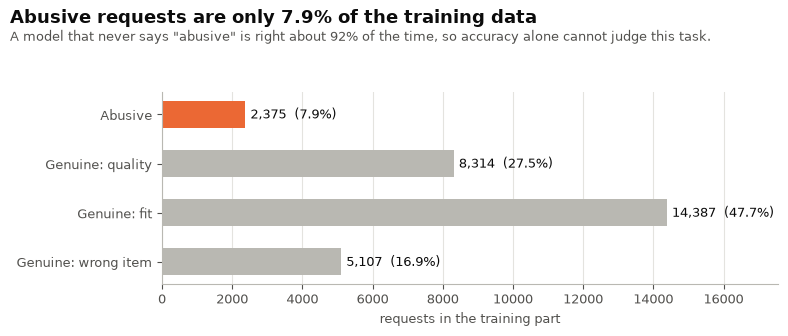

accuracy of "never abusive": 0.921 | accuracy of always predicting the largest class (Genuine: fit): 0.477


In [4]:
# Chart style: emphasis colouring (abusive = accent, genuine classes = grey); categorical slots from the validated reference palette.
INK, MUTED, GRID, GREY = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b2"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
FIG = REPORTS / "figures"
FIG.mkdir(exist_ok=True)


def style(ax, grid_axis="x"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def title(fig, headline, sub=None):
    fig.text(0.01, 0.98, headline, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    if sub:
        fig.text(0.01, 0.915, sub, ha="left", va="top", fontsize=9.5, color=MUTED)


names = {
    "abusive": "Abusive",
    "genuine_quality_issue": "Genuine: quality",
    "genuine_fit_issue": "Genuine: fit",
    "genuine_wrong_item": "Genuine: wrong item",
}
counts = parts["train"]["label"].value_counts().reindex(LABELS)
share = counts / counts.sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
fig.subplots_adjust(top=0.72, left=0.2, right=0.97, bottom=0.12)
bars = ax.barh(
    [names[l] for l in LABELS][::-1],
    counts.to_numpy()[::-1],
    height=0.55,
    color=[ORANGE if l == "abusive" else GREY for l in LABELS][::-1],
)
for bar, n, p_ in zip(bars, counts.to_numpy()[::-1], share.to_numpy()[::-1]):
    ax.text(
        bar.get_width() + counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{n:,}  ({p_:.1%})",
        va="center",
        fontsize=9,
        color=INK,
    )
ax.set_xlim(0, counts.max() * 1.22)
ax.set_xlabel("requests in the training part", color=MUTED, fontsize=9)
style(ax)
title(
    fig,
    f"Abusive requests are only {share['abusive']:.1%} of the training data",
    'A model that never says "abusive" is right about 92% of the time, so accuracy alone cannot judge this task.',
)
fig.savefig(FIG / "phase5_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    f'accuracy of "never abusive": {1 - share["abusive"]:.3f} | accuracy of always predicting the largest class ({names[share.idxmax()]}): {share.max():.3f}'
)

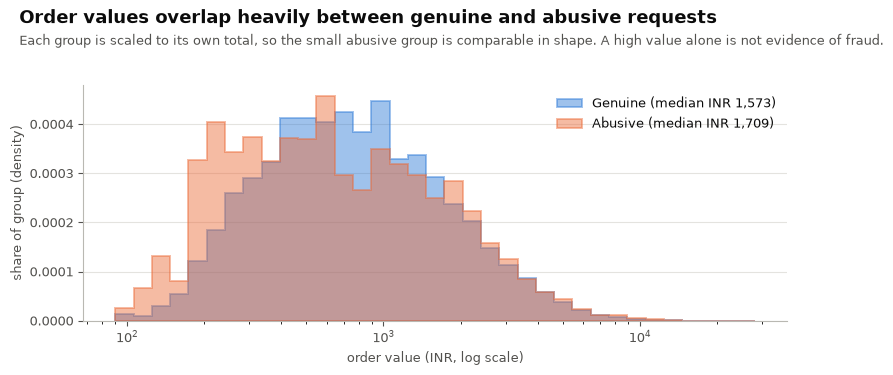

abusive rate by order-value quintile (is value alone informative?):
                   abusive_rate  rows
order_value_inr                      
(89.999, 719.0]          0.0845  6081
(719.0, 1259.0]          0.0638  5999
(1259.0, 1963.0]         0.0746  6036
(1963.0, 3199.0]         0.0854  6051
(3199.0, 28197.0]        0.0849  6016


In [5]:
tr = parts["train"]
is_abusive = tr["label"] == "abusive"
bins = np.logspace(np.log10(max(tr["order_value_inr"].min(), 1)), np.log10(tr["order_value_inr"].max()), 36)
fig, ax = plt.subplots(figsize=(8, 3.8))
fig.subplots_adjust(top=0.78, left=0.09, right=0.97, bottom=0.16)
for mask, colour, label in ((~is_abusive, BLUE, "Genuine"), (is_abusive, ORANGE, "Abusive")):
    ax.hist(
        tr.loc[mask, "order_value_inr"],
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.45,
        color=colour,
        edgecolor=colour,
        linewidth=1.4,
        label=f"{label} (median INR {tr.loc[mask, 'order_value_inr'].median():,.0f})",
    )
ax.set_xscale("log")
ax.set_xlabel("order value (INR, log scale)", color=MUTED, fontsize=9)
ax.set_ylabel("share of group (density)", color=MUTED, fontsize=9)
ax.legend(frameon=False, fontsize=9, labelcolor=INK)
style(ax, "y")
title(
    fig,
    "Order values overlap heavily between genuine and abusive requests",
    "Each group is scaled to its own total, so the small abusive group is comparable in shape. A high value alone is not evidence of fraud.",
)
fig.savefig(FIG / "phase5_order_value_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
band = pd.qcut(tr["order_value_inr"], 5, duplicates="drop")
print("abusive rate by order-value quintile (is value alone informative?):")
print(
    is_abusive.groupby(band, observed=True)
    .agg(["mean", "size"])
    .rename(columns={"mean": "abusive_rate", "size": "rows"})
    .round(4)
    .to_string()
)

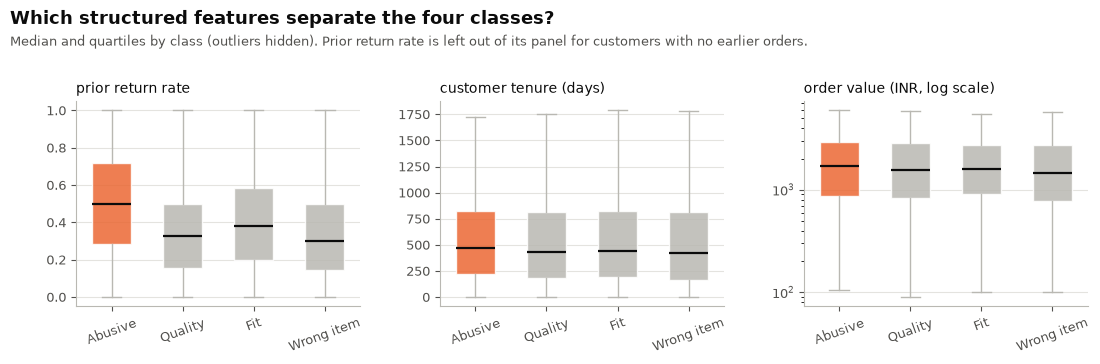

,prior_return_rate,customer_tenure_days,order_value_inr
label,,,
abusive,0.500,468.0,1709.0
genuine_quality_issue,0.329,431.0,1574.0
genuine_fit_issue,0.381,437.0,1599.0
genuine_wrong_item,0.300,419.0,1449.0


In [6]:
features = [
    ("prior_return_rate", "prior return rate", False),
    ("customer_tenure_days", "customer tenure (days)", False),
    ("order_value_inr", "order value (INR, log scale)", True),
]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
fig.subplots_adjust(top=0.74, left=0.07, right=0.99, bottom=0.2, wspace=0.28)
short = {
    "abusive": "Abusive",
    "genuine_quality_issue": "Quality",
    "genuine_fit_issue": "Fit",
    "genuine_wrong_item": "Wrong item",
}
for ax, (column, label, log) in zip(axes, features):
    groups = [tr.loc[tr["label"] == l, column].dropna().to_numpy() for l in LABELS]
    box = ax.boxplot(
        groups,
        tick_labels=[short[l] for l in LABELS],
        patch_artist=True,
        widths=0.55,
        showfliers=False,
        medianprops={"color": INK, "linewidth": 1.6},
        whiskerprops={"color": GREY},
        capprops={"color": GREY},
    )
    for patch, l in zip(box["boxes"], LABELS):
        patch.set_facecolor(ORANGE if l == "abusive" else GREY)
        patch.set_alpha(0.85)
        patch.set_edgecolor("white")
    if log:
        ax.set_yscale("log")
    ax.set_title(label, fontsize=10, color=INK, loc="left")
    ax.tick_params(axis="x", labelrotation=20)
    style(ax, "y")
title(
    fig,
    "Which structured features separate the four classes?",
    "Median and quartiles by class (outliers hidden). Prior return rate is left out of its panel for customers with no earlier orders.",
)
fig.savefig(FIG / "phase5_feature_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
tr.groupby("label")[["prior_return_rate", "customer_tenure_days", "order_value_inr"]].median().reindex(LABELS).round(3)

## 4. Preprocessing (fitted on train only) and Phase 4 text scores (out-of-fold)
* `FeaturePreprocessor` (Phase 3) is fitted on the train part; the calibration and test parts are only transformed.
* Phase 4's selected text model (word TF-IDF + Logistic Regression) gives `txt_p_*`. For **train** rows the scores are rolling-origin out-of-fold (each month scored by a model fitted on strictly earlier months; the first 60 days use grouped OOF inside that window); calibration and test rows are scored by a model fitted on train only. No in-sample text predictions are used.
* Two feature arms: **A** structured only | **C** structured + Phase 4 text scores + rule/shape indicators + text-reuse history (Phase 4 findings). (The text-scores-only arm B was dropped to keep the run short; Phase 4 already compared it.)

In [7]:
pre = FeaturePreprocessor(cfg).fit(parts["train"])
text_params = {**cfg["text"], "svm_c": 0.5}
text_model = TextCandidate("word", "logreg", text_params, SEED)
oof_scores, oof_kind, oof_fit_end, _ = rolling_origin_out_of_fold(
    text_model,
    parts["train"]["customer_reason"],
    parts["train"]["label"],
    parts["train"]["customer_id"],
    parts["train"]["return_request_date"],
    60,
    int(cfg["validation"]["text_oof_folds"]),
)
print("time-aware text scores:", check_rolling(oof_kind, oof_fit_end, parts["train"]["return_request_date"]))
fitted_text = text_model.fit(parts["train"]["customer_reason"], parts["train"]["label"])
text_scores = {
    "train": oof_scores,
    **{n: fitted_text.scores(parts[n]["customer_reason"]) for n in ("calibration", "test")},
}
text_cols = [f"txt_p_{label}" for label in LABELS]

reuse = ["hist_same_text", "hist_max_text_sim", "hist_n_similar_text"]
rules = [c for c in tabular_columns(frame) if c.startswith(("ev_", "txt_len", "txt_n_", "txt_upper", "txt_has"))]
extra_scaler = StandardScaler().fit(parts["train"][rules + reuse])  # learned on train only (needed by linear models)
ARMS = {"A structured": [], "C + all text-derived": text_cols + rules + reuse}


def matrix(kind, part, arm):
    rows = parts[part]
    base = pre.transform_linear(rows) if kind == "linear" else pre.transform_tree(rows)
    base = base.reset_index(drop=True)
    pieces = [base]
    if ARMS[arm]:
        pieces.append(pd.DataFrame(text_scores[part], columns=text_cols))
    if arm.startswith("C"):
        extra = rows[rules + reuse].reset_index(drop=True)
        pieces.append(pd.DataFrame(extra_scaler.transform(extra), columns=rules + reuse) if kind == "linear" else extra)
    out = pd.concat(pieces, axis=1)
    assert len(out) == len(rows) and not out.columns.duplicated().any()
    return out


demo = matrix("linear", "test", "C + all text-derived")
print("linear matrix for arm C:", demo.shape, "| NaNs:", int(demo.isna().sum().sum()))
print("tree matrix for arm C  :", matrix("tree", "test", "C + all text-derived").shape)
print("preprocessor dropped (constant/duplicate on train):", len(pre.dropped_columns_), "columns")

time-aware text scores: {'rows': 30183, 'rolling_rows': 20386, 'grouped_initial_rows': 9797, 'rows_without_kind': 0, 'rolling_rows_scored_with_future_data': 0}


linear matrix for arm C: (8497, 204) | NaNs: 0
tree matrix for arm C  : (8497, 90)
preprocessor dropped (constant/duplicate on train): 9 columns


## 5. Train the baselines
Fixed settings (no tuning): Dummy = class prior; Logistic Regression C=1; Decision Tree depth 6, leaf >= 100; Random Forest / Extra Trees 100 trees, leaf >= 5; HistGradientBoosting 150 iterations, lr 0.08, 31 leaves, L2 5.
Stochastic models run with 2 seeds; Dummy, Logistic Regression and the Decision Tree are deterministic. Each model is trained on both feature arms (Dummy ignores features, so it runs once).
For every run: four-class probabilities, P(abusive) raw and isotonic-calibrated (calibrator fitted on the calibration part only), and routing by expected cost under the official matrix.

In [8]:
y_idx = {n: parts[n]["label"].map(LABELS.index).to_numpy() for n in parts}
y_abuse = {n: (y_idx[n] == LABELS.index("abusive")).astype(int) for n in parts}
runs, store = [], {}


def evaluate(model_name, arm, seed, probs_cal, probs_test, seconds):
    ab = LABELS.index("abusive")
    raw_cal, raw_test = probs_cal[:, ab], probs_test[:, ab]
    calibrator = AbuseCalibrator("isotonic").fit(raw_cal, y_abuse["calibration"])
    cal_test = calibrator.transform(raw_test)
    report = classification_report(probs_test, parts["test"]["label"])
    row = {
        "model": model_name,
        "arm": arm,
        "seed": seed,
        "seconds": round(seconds, 1),
        "macro_f1": report["macro_f1"],
        "accuracy": report["accuracy"],
        "abusive_precision": report["per_class"].loc["abusive", "precision"],
        "abusive_recall": report["per_class"].loc["abusive", "recall"],
        "log_loss_4class": float(log_loss(y_idx["test"], np.clip(probs_test, 1e-4, 1), labels=range(4))),
    }
    row.update({f"raw_{k}": v for k, v in abuse_metrics(y_abuse["test"], raw_test).items()})
    row.update(
        {
            f"cal_{k}": v
            for k, v in abuse_metrics(y_abuse["test"], cal_test).items()
            if k in ("abuse_log_loss", "abuse_ECE")
        }
    )
    row.update({f"raw_{k}": v for k, v in business_cost(raw_test, y_abuse["test"], cfg).items()})
    row.update({f"cal_{k}": v for k, v in business_cost(cal_test, y_abuse["test"], cfg).items()})
    runs.append(row)
    store[(model_name, arm, seed)] = {"probs": probs_test, "raw": raw_test, "cal": cal_test, "report": report}


def train_model(name):
    arms = ["A structured"] if name == "dummy" else list(ARMS)
    seeds = SEEDS if name in STOCHASTIC else (0,)
    for arm in arms:
        kind = MATRIX_KIND[name]
        x_train, x_cal, x_test = (matrix(kind, p, arm) for p in ("train", "calibration", "test"))
        cat_names = []
        if name == "catboost":  # convert categoricals to strings ONCE (not inside the seed loop)
            x_train, cat_names = catboost_inputs(x_train)
            x_cal, x_test = catboost_inputs(x_cal)[0], catboost_inputs(x_test)[0]
        for seed in seeds:
            started = time.perf_counter()
            if name == "catboost":
                model = build_model(name, seed, cat_names).fit(x_train, y_idx["train"])
            else:
                model = build_model(name, seed).fit(x_train, y_idx["train"])
            probs_cal, probs_test = predict_full(model, x_cal), predict_full(model, x_test)
            evaluate(name, arm, seed, probs_cal, probs_test, time.perf_counter() - started)


def summary_of(name):
    table = (
        pd.DataFrame([r for r in runs if r["model"] == name])
        .groupby("arm")[
            [
                "macro_f1",
                "raw_abuse_AP",
                "raw_abuse_log_loss",
                "raw_abuse_ECE",
                "cal_abuse_ECE",
                "raw_saving_vs_approve_all",
                "cal_saving_vs_approve_all",
                "seconds",
            ]
        ]
        .mean()
        .round(4)
    )
    display(table)

In [9]:
train_model("dummy")
summary_of("dummy")

,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.1652,0.0823,0.2844,0.0138,0.0218,0.0,0.0,0.0


In [10]:
train_model("logreg")
summary_of("logreg")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.4800,0.4494,0.2066,0.0053,0.0169,0.1096,0.0641,22.4
C + all text-derived,0.8043,0.5563,0.1825,0.0058,0.0160,0.1913,0.1771,18.3


In [11]:
train_model("decision_tree")
summary_of("decision_tree")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.4579,0.3797,0.2129,0.0066,0.0160,0.0883,0.0648,0.4
C + all text-derived,0.7472,0.3759,0.2148,0.0078,0.0191,0.0559,0.0465,0.6


In [12]:
train_model("random_forest")
summary_of("random_forest")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.4850,0.5752,0.1850,0.0299,0.0147,0.1505,0.1848,3.90
C + all text-derived,0.7976,0.6617,0.1753,0.0408,0.0137,0.2007,0.2148,4.35


In [13]:
train_model("extra_trees")
summary_of("extra_trees")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.4298,0.4937,0.2007,0.0258,0.0172,0.1142,0.1247,3.80
C + all text-derived,0.7647,0.5893,0.1861,0.0364,0.0141,0.1492,0.1816,4.25


In [14]:
train_model("hist_gb")
summary_of("hist_gb")

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.5516,0.6567,0.1548,0.0071,0.0138,0.2672,0.2305,6.85
C + all text-derived,0.8641,0.7263,0.1377,0.0072,0.0113,0.2777,0.2660,10.20


**CatBoost** (gradient boosting with native categorical handling) is the seventh baseline. Fixed settings: 200 iterations, depth 6, learning rate 0.08, L2 5.

In [15]:
train_model("catboost")
summary_of("catboost")

,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE,cal_abuse_ECE,raw_saving_vs_approve_all,cal_saving_vs_approve_all,seconds
arm,,,,,,,,
A structured,0.5333,0.6126,0.1695,0.0159,0.0159,0.2064,0.2185,41.65
C + all text-derived,0.8459,0.7045,0.1480,0.0159,0.0138,0.2920,0.3019,43.75


**Optional text-only baseline - Multinomial Naive Bayes** on word TF-IDF (non-negative features, as the document requires). It sees only `customer_reason`, so it shows what text alone achieves beyond Phase 4's linear model.

In [16]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, preprocessor=normalise_reason)
x_tr = vectorizer.fit_transform(parts["train"]["customer_reason"])
nb = MultinomialNB(alpha=0.5).fit(x_tr, y_idx["train"])
nb_probs = {n: nb.predict_proba(vectorizer.transform(parts[n]["customer_reason"])) for n in ("calibration", "test")}
evaluate("naive_bayes_text", "text only", 0, nb_probs["calibration"], nb_probs["test"], 0.0)
pd.DataFrame(runs[-1:])[["model", "macro_f1", "raw_abuse_AP", "raw_abuse_log_loss", "raw_abuse_ECE"]].round(4)

/home/claude/r2_project/FULL_CODE/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,model,macro_f1,raw_abuse_AP,raw_abuse_log_loss,raw_abuse_ECE
0,naive_bayes_text,0.6834,0.1478,0.3298,0.0477


## 6. Comparison, per-class metrics and confusion matrices
All numbers below are on the same test (validation-period) rows. Means over seeds; `sd` is the seed spread of the saving.

In [17]:
results = pd.DataFrame(runs)
agg = (
    results.groupby(["model", "arm"])
    .agg(
        macro_f1=("macro_f1", "mean"),
        accuracy=("accuracy", "mean"),
        abusive_precision=("abusive_precision", "mean"),
        abusive_recall=("abusive_recall", "mean"),
        log_loss_4class=("log_loss_4class", "mean"),
        abuse_AP=("raw_abuse_AP", "mean"),
        raw_log_loss=("raw_abuse_log_loss", "mean"),
        raw_ECE=("raw_abuse_ECE", "mean"),
        cal_log_loss=("cal_abuse_log_loss", "mean"),
        cal_ECE=("cal_abuse_ECE", "mean"),
        raw_saving=("raw_saving_vs_approve_all", "mean"),
        cal_saving=("cal_saving_vs_approve_all", "mean"),
        saving_sd=("cal_saving_vs_approve_all", "std"),
        genuine_escalated=("cal_genuine_escalated", "mean"),
        abusive_approved=("cal_abusive_approved", "mean"),
        seeds=("seed", "nunique"),
    )
    .fillna({"saving_sd": 0.0})
    .round(4)
)
order = {m: i for i, m in enumerate([*MODEL_ORDER, "naive_bayes_text"])}
agg = agg.sort_index(key=lambda idx: idx.map(order) if idx.name == "model" else idx)
agg.to_csv(REPORTS / "phase5_model_comparison.csv")
agg

macro_f1  accuracy  abusive_precision  abusive_recall  log_loss_4class  abuse_AP  raw_log_loss  raw_ECE  cal_log_loss  cal_ECE  raw_saving  cal_saving  saving_sd  \
model            arm                                                                                                                                                                                       
dummy            A structured            0.1652    0.4935             0.0000          0.0000           1.1879    0.0823        0.2844   0.0138        0.2864   0.0218      0.0000      0.0000     0.0000   
logreg           A structured            0.4800    0.5690             0.5491          0.3362           0.9347    0.4494        0.2066   0.0053        0.2112   0.0169      0.1096      0.0641     0.0000   
                 C + all text-derived    0.8043    0.8960             0.6321          0.3662           0.2853    0.5563        0.1825   0.0058        0.1873   0.0160      0.1913      0.1771     0.0000   
decision_tree    A structured            0.4579    0.5564             0.5357          0.2790           0.9345    0.3797        0.2129   0.0066        0.2165   0.0160      0.0883      0.0648     0.0000   
                 C + all text-derived    0.7472    0.8797             0.4960          0.1760           0.3342    0.3759        0.2148   0.0078        0.2184   0.0191      0.0559      0.0465     0.0000   
random_forest    A structured            0.4850    0.5780             0.7144          0.3598           0.9102    0.5752        0.1850   0.0299        0.1795   0.0147      0.1505      0.1848     0.0080   
                 C + all text-derived    0.7976    0.9007             0.8604          0.2869           0.3078    0.6617        0.1753   0.0408        0.1606   0.0137      0.2007      0.2148     0.0414   
extra_trees      A structured            0.4298    0.5707             0.6614          0.2682           0.9409    0.4937        0.2007   0.0258        0.1992   0.0172      0.1142      0.1247     0.0217   
                 C + all text-derived    0.7647    0.8928             0.8000          0.1946           0.3288    0.5893        0.1861   0.0364        0.1761   0.0141      0.1492      0.1816     0.0035   
hist_gb          A structured            0.5516    0.5886             0.6863          0.5665           0.8725    0.6567        0.1548   0.0071        0.1581   0.0138      0.2672      0.2305     0.0000   
                 C + all text-derived    0.8641    0.9170             0.7968          0.5722           0.2329    0.7263        0.1377   0.0072        0.1415   0.0113      0.2777      0.2660     0.0000   
catboost         A structured            0.5333    0.5883             0.6881          0.4506           0.8712    0.6126        0.1695   0.0159        0.1697   0.0159      0.2064      0.2185     0.0132   
                 C + all text-derived    0.8459    0.9133             0.8170          0.4692           0.2383    0.7045        0.1480   0.0159        0.1494   0.0138      0.2920      0.3019     0.0098   
naive_bayes_text text only               0.6834    0.8770             0.5000          0.0100           0.4592    0.1478        0.3298   0.0477        0.2755   0.0164     -0.0029      0.0000     0.0000   

                                       genuine_escalated  abusive_approved  seeds  
model            arm                                                               
dummy            A structured                        0.0             699.0      1  
logreg           A structured                        0.0             613.0      1  
                 C + all text-derived                0.0             454.0      1  
decision_tree    A structured                        0.0             590.0      1  
                 C + all text-derived                0.0             614.0      1  
random_forest    A structured                        1.5             403.0      2  
                 C + all text-derived                4.5             379.0      2  
extra_trees      A

In [18]:
per_class = []
for (name, arm, seed), item in store.items():
    if seed != 0:
        continue
    table = item["report"]["per_class"].copy()
    table.insert(0, "arm", arm)
    table.insert(0, "model", name)
    per_class.append(table.reset_index(names="class"))
per_class = pd.concat(per_class)
per_class.to_csv(REPORTS / "phase5_per_class_metrics.csv", index=False)
print("per-class F1 (seed 0), arm A and arm C:")
per_class[per_class.arm.isin(["A structured", "C + all text-derived"])].pivot_table(
    index=["model", "arm"], columns="class", values="f1"
).round(3)

per-class F1 (seed 0), arm A and arm C:


class                               abusive  genuine_fit_issue  genuine_quality_issue  genuine_wrong_item
model         arm                                                                                        
catboost      A structured            0.540              0.683                  0.457               0.446
              C + all text-derived    0.598              0.957                  0.903               0.926
decision_tree A structured            0.367              0.676                  0.374               0.415
              C + all text-derived    0.260              0.946                  0.871               0.911
dummy         A structured            0.000              0.661                  0.000               0.000
extra_trees   A structured            0.385              0.696                  0.378               0.269
              C + all text-derived    0.320              0.953                  0.884               0.909
hist_gb       A structured            0.621              0.675                  0.474               0.436
              C + all text-derived    0.666              0.958                  0.903               0.930
logreg        A structured            0.417              0.682                  0.418               0.403
              C + all text-derived    0.464              0.952                  0.889               0.912
random_forest A structured            0.489              0.694                  0.407               0.376
              C + all text-derived    0.440              0.954                  0.892               0.916

In [19]:
confusions = []
for (name, arm, seed), item in store.items():
    if seed == 0:
        confusions.append(item["report"]["confusion"].assign(model=name, arm=arm).reset_index(names="truth"))
pd.concat(confusions).to_csv(REPORTS / "phase5_confusion_matrices.csv", index=False)
print(
    "confusion matrix (rows = truth, columns = prediction; class order:",
    list(LABELS),
    ") for Logistic Regression arm C:",
)
store[("logreg", "C + all text-derived", 0)]["report"]["confusion"]

confusion matrix (rows = truth, columns = prediction; class order: ['abusive', 'genuine_quality_issue', 'genuine_fit_issue', 'genuine_wrong_item'] ) for Logistic Regression arm C:


,pred_abusive,pred_genuine_quality_issue,pred_genuine_fit_issue,pred_genuine_wrong_item
true_abusive,256,241,116,86
true_genuine_quality_issue,83,2264,90,16
true_genuine_fit_issue,50,100,4030,13
true_genuine_wrong_item,16,36,37,1063


### 6b. Model comparison (macro-F1 and abusive-class precision / recall)
Full feature arm (C), mean over seeds. **Precision and recall are for the argmax four-class decision**, i.e. "the model's single most likely class is abusive". The routing in section 8 uses cost-based thresholds instead and flags far more requests, so these bars understate what routing catches (see `abusive_approved` in the table above). The chart exists to expose models whose macro-F1 hides a missing abusive class.

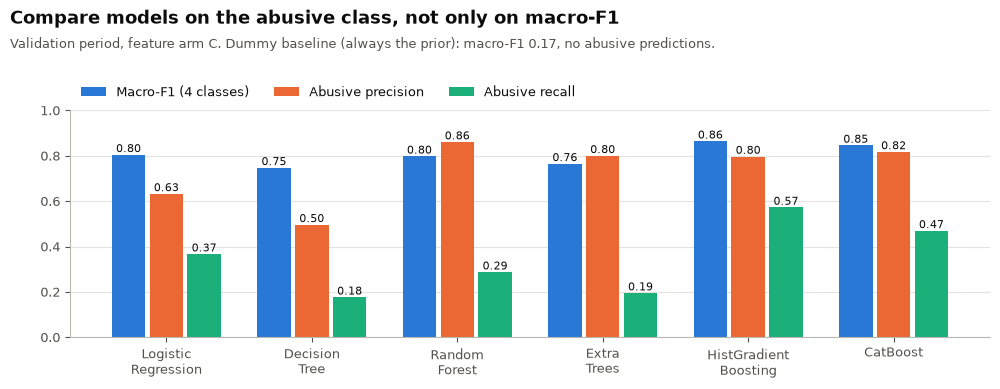

,macro_f1,abusive_precision,abusive_recall,abuse_AP,cal_saving,genuine_escalated,abusive_approved
model,,,,,,,
logreg,0.804,0.632,0.366,0.556,0.177,0.0,454.0
decision_tree,0.747,0.496,0.176,0.376,0.046,0.0,614.0
random_forest,0.798,0.860,0.287,0.662,0.215,4.5,379.0
extra_trees,0.765,0.800,0.195,0.589,0.182,1.0,451.5
hist_gb,0.864,0.797,0.572,0.726,0.266,7.0,287.0
catboost,0.846,0.817,0.469,0.704,0.302,1.0,303.5


In [20]:
arm_c = agg.xs("C + all text-derived", level="arm").reindex([m for m in MODEL_ORDER if m != "dummy"])
fig, ax = plt.subplots(figsize=(10, 4.2))
fig.subplots_adjust(top=0.74, left=0.07, right=0.99, bottom=0.2)
positions = np.arange(len(arm_c))
width = 0.26
metrics = [
    ("macro_f1", "Macro-F1 (4 classes)", BLUE),
    ("abusive_precision", "Abusive precision", ORANGE),
    ("abusive_recall", "Abusive recall", AQUA),
]
for offset, (column, label, colour) in zip((-width, 0, width), metrics):
    bars = ax.bar(positions + offset, arm_c[column], width=width - 0.03, color=colour, label=label)
    for bar, value in zip(bars, arm_c[column]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.012, f"{value:.2f}", ha="center", fontsize=8, color=INK)
ax.set_xticks(positions)
ax.set_xticklabels(
    ["Logistic\nRegression", "Decision\nTree", "Random\nForest", "Extra\nTrees", "HistGradient\nBoosting", "CatBoost"],
    fontsize=9,
)
ax.set_ylim(0, 1.0)
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9, labelcolor=INK)
style(ax, "y")
dummy_f1 = agg.loc[("dummy", "A structured"), "macro_f1"]
title(
    fig,
    "Compare models on the abusive class, not only on macro-F1",
    f"Validation period, feature arm C. Dummy baseline (always the prior): macro-F1 {dummy_f1:.2f}, no abusive predictions.",
)
fig.savefig(FIG / "phase5_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
arm_c[
    [
        "macro_f1",
        "abusive_precision",
        "abusive_recall",
        "abuse_AP" if "abuse_AP" in arm_c else "cal_saving",
        "cal_saving",
        "genuine_escalated",
        "abusive_approved",
    ]
].round(3)

## 7. Probability quality and calibration limits
The classifier outputs are **not assumed calibrated**. Raw vs isotonic-calibrated log loss and ECE for P(abusive) are in the comparison table. Tree ensembles with averaged leaves are usually under-confident,
the Decision Tree is coarse (few distinct values), and the calibrator is fitted on only ~4,400 rows, so the calibrated numbers carry sampling noise.

In [21]:
view = agg[["abuse_AP", "raw_log_loss", "cal_log_loss", "raw_ECE", "cal_ECE", "raw_saving", "cal_saving"]]
print("effect of calibration (positive = calibration helped):")
effect = pd.DataFrame(
    {
        "log_loss_gain": view.raw_log_loss - view.cal_log_loss,
        "ECE_gain": view.raw_ECE - view.cal_ECE,
        "saving_gain": view.cal_saving - view.raw_saving,
    }
).round(4)
display(effect)
best_for_plot = ("logreg", "C + all text-derived")
item = store[(*best_for_plot, 0)]
reliability = pd.concat(
    [
        reliability_table(y_abuse["test"], item["raw"]).assign(version="raw"),
        reliability_table(y_abuse["test"], item["cal"]).assign(version="isotonic"),
    ]
)
reliability.to_csv(REPORTS / "phase5_reliability_logreg.csv", index=False)
print("reliability, Logistic Regression arm C (10 equal-count bins; observed should match predicted):")
reliability

effect of calibration (positive = calibration helped):


log_loss_gain  ECE_gain  saving_gain
model            arm                                                       
dummy            A structured                -0.0020   -0.0080       0.0000
logreg           A structured                -0.0046   -0.0116      -0.0455
                 C + all text-derived        -0.0048   -0.0102      -0.0142
decision_tree    A structured                -0.0036   -0.0094      -0.0235
                 C + all text-derived        -0.0036   -0.0113      -0.0094
random_forest    A structured                 0.0055    0.0152       0.0343
                 C + all text-derived         0.0147    0.0271       0.0141
extra_trees      A structured                 0.0015    0.0086       0.0105
                 C + all text-derived         0.0100    0.0223       0.0324
hist_gb          A structured                -0.0033   -0.0067      -0.0367
                 C + all text-derived        -0.0038   -0.0041      -0.0117
catboost         A structured                -0.0002    0.0000       0.0121
                 C + all text-derived        -0.0014    0.0021       0.0099
naive_bayes_text text only                    0.0543    0.0313       0.0029

reliability, Logistic Regression arm C (10 equal-count bins; observed should match predicted):


,rows,mean_predicted,observed_rate,version
0,850,0.0006,0.0024,raw
1,850,0.0019,0.0024,raw
2,850,0.0039,0.0035,raw
3,850,0.0069,0.0118,raw
4,850,0.0117,0.0188,raw
5,850,0.0201,0.0329,raw
6,850,0.0357,0.0435,raw
7,849,0.0668,0.0695,raw
8,849,0.1491,0.1484,raw
9,849,0.5093,0.4900,raw


## 8. Classifier, routing and the two together
**(a) Classifier** - four-class quality (section 6). **(b) Routing** - the cost of the decisions it induces, using the official matrix (genuine: approve 0 / inspect 0.5 / escalate 10; abusive: approve 1 / inspect 0.3 / escalate 0),
with decisions from `router.route` (minimum expected cost). `saving` = 1 - cost / cost of approving everything. **(c) Together** - the official scorer on the calibrated routing (seed 0), including the fairness component
(new vs established, low value vs other, non-English vs English; measured on genuine customers only). Baselines give a generic justification, so the justification part of the official score is not meaningful here.

In [22]:
official_rows = []
for (name, arm, seed), item in store.items():
    if seed != 0 or name in ("dummy", "naive_bayes_text"):
        continue
    decisions = route(item["cal"], cfg)
    predictions = pd.DataFrame(
        {
            "return_id": parts["test"]["return_id"],
            "decision": decisions,
            "confidence": item["cal"],
            "justification": "baseline model output without a text explanation",
        }
    )
    result = official_score(predictions, parts["test"])
    fairness = audit(parts["test"], pd.Series(decisions, index=parts["test"].index), cfg)
    official_rows.append(
        {
            "model": name,
            "arm": arm,
            "official_primary": result["primary_score"],
            "fairness_score": fairness["fairness_score"],
            "new_vs_established_ratio": fairness["new_vs_established"].get("ratio"),
            **{f"component_{k}": v for k, v in result["components"].items() if isinstance(v, int | float)},
        }
    )
official = pd.DataFrame(official_rows).set_index(["model", "arm"]).round(4)
official.to_csv(REPORTS / "phase5_official_scores.csv")
official

official_primary  fairness_score  new_vs_established_ratio  component_savings  component_fairness_score  component_fairness_credit  component_fairness_effective  \
model         arm                                                                                                                                                                                      
logreg        A structured                    0.0954          0.7883                    1.3274             0.0641                    0.7883                     0.3205                        0.2526   
              C + all text-derived            0.2688          0.8175                    1.0394             0.1771                    0.8175                     0.8856                        0.7239   
decision_tree A structured                    0.1032          0.8930                    1.2359             0.0648                    0.8930                     0.3240                        0.2894   
              C + all text-derived            0.0632          0.6603                    1.6231             0.0465                    0.6603                     0.2325                        0.1535   
random_forest A structured                    0.2347          0.5324                    1.3754             0.1904                    0.5324                     0.9521                        0.5068   
              C + all text-derived            0.2708          0.7592                    1.0627             0.1856                    0.7592                     0.9278                        0.7043   
extra_trees   A structured                    0.1326          0.5134                    1.5137             0.1093                    0.5134                     0.5465                        0.2806   
              C + all text-derived            0.2396          0.6379                    1.4637             0.1791                    0.6379                     0.8956                        0.5713   
hist_gb       A structured                    0.2861          0.6240                    1.3920             0.2305                    0.6240                     1.0000                        0.6240   
              C + all text-derived            0.2891          0.5148                    1.4128             0.2660                    0.5148                     1.0000                        0.5148   
catboost      A structured                    0.2838          0.6870                    1.3280             0.2092                    0.6870                     1.0000                        0.6870   
              C + all text-derived            0.3631          0.7345                    1.1448             0.3089                    0.7345                     1.0000                        0.7345   

                                    component_size_chart_score  
model         arm                                               
logreg        A structured                                 0.0  
              C + all text-derived                         0.0  
decision_tree A structured                                 0.0  
              C + all text-derived                         0.0  
random_forest A structured                                 0.0  
              C + all text-derived                         0.0  
extra_trees   A structured                                 0.0  
              C + all text-derived                         0.0  
hist_gb       A structured                                 0.0  
              C + all text-derived                         0.0  
catboost      A structured                                 0.0  
              C + all text-derived                         0.0

## 9. Selection by evidence
Rule, written before looking at results: rank by the **calibrated routing saving** (the official objective). Choose the **simplest** model (`Dummy < LogReg < Tree < RF < ExtraTrees < HistGB < CatBoost`, then arm A < C)
whose saving is within one seed standard deviation (at least 0.005) of the best. Dummy and Naive Bayes are references only and cannot be selected.

In [23]:
candidates = agg.drop(index=["dummy", "naive_bayes_text"], level="model")
best_row = candidates["cal_saving"].idxmax()
tolerance = max(candidates.loc[best_row, "saving_sd"], 0.005)
eligible = candidates[candidates["cal_saving"] >= candidates.loc[best_row, "cal_saving"] - tolerance]
arm_rank = {a: i for i, a in enumerate(ARMS)}
chosen = min(eligible.index, key=lambda ix: (order[ix[0]], arm_rank[ix[1]]))
print(
    "best by calibrated saving:",
    best_row,
    round(candidates.loc[best_row, "cal_saving"], 4),
    "| tolerance",
    round(tolerance, 4),
)
print("selected baseline:", chosen)
print(
    "dummy reference (arm A): saving",
    agg.loc[("dummy", "A structured"), "cal_saving"],
    "| macro-F1",
    agg.loc[("dummy", "A structured"), "macro_f1"],
)
agg.loc[[chosen]]

best by calibrated saving: ('catboost', 'C + all text-derived') 0.3019 | tolerance 0.0098
selected baseline: ('catboost', 'C + all text-derived')
dummy reference (arm A): saving 0.0 | macro-F1 0.1652


,,macro_f1,accuracy,abusive_precision,abusive_recall,log_loss_4class,abuse_AP,raw_log_loss,raw_ECE,cal_log_loss,cal_ECE,raw_saving,cal_saving,saving_sd,genuine_escalated,abusive_approved,seeds
model,arm,,,,,,,,,,,,,,,,
catboost,C + all text-derived,0.8459,0.9133,0.817,0.4692,0.2383,0.7045,0.148,0.0159,0.1494,0.0138,0.292,0.3019,0.0098,1.0,303.5,2


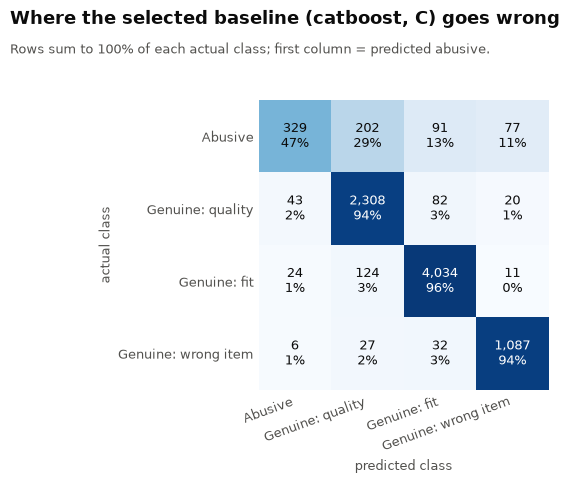

genuine requests predicted abusive: 73 of 7,798 (0.9%)
abusive requests predicted genuine: 370 of 699 (52.9%)


In [24]:
cm = store[(*chosen, 0)]["report"]["confusion"]
row_share = cm.div(cm.sum(axis=1), axis=0)
labels_short = [names[l] for l in LABELS]
fig, ax = plt.subplots(figsize=(6.4, 5.0))
fig.subplots_adjust(top=0.8, left=0.3, right=0.95, bottom=0.22)
ax.imshow(row_share.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels(labels_short, rotation=20, ha="right", fontsize=9)
ax.set_yticks(range(4))
ax.set_yticklabels(labels_short, fontsize=9)
ax.set_xlabel("predicted class", color=MUTED, fontsize=9)
ax.set_ylabel("actual class", color=MUTED, fontsize=9)
for i in range(4):
    for j in range(4):
        value = row_share.iat[i, j]
        ax.text(
            j,
            i,
            f"{cm.iat[i, j]:,}\n{value:.0%}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > 0.55 else INK,
        )
for side in ax.spines.values():
    side.set_visible(False)
ax.tick_params(colors=MUTED, length=0)
title(
    fig,
    f"Where the selected baseline ({chosen[0]}, {chosen[1][0]}) goes wrong",
    "Rows sum to 100% of each actual class; first column = predicted abusive.",
)
fig.savefig(FIG / "phase5_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    f"genuine requests predicted abusive: {int(cm.iloc[1:, 0].sum()):,} of {int(cm.iloc[1:].to_numpy().sum()):,} ({cm.iloc[1:, 0].sum() / cm.iloc[1:].to_numpy().sum():.1%})"
)
print(
    f"abusive requests predicted genuine: {int(cm.iloc[0, 1:].sum()):,} of {int(cm.iloc[0].sum()):,} ({cm.iloc[0, 1:].sum() / cm.iloc[0].sum():.1%})"
)

In [25]:
sel = store[(*chosen, 0)]
sel_decisions = pd.Series(route(sel["cal"], cfg), index=parts["test"].index)
view = parts["test"][
    ["customer_reason", "label", "customer_tenure_days", "prior_orders_count", "payment_method", "order_value_inr"]
].copy()
view["p_abusive_cal"] = sel["cal"].round(3)
view["decision"] = sel_decisions
print(
    "abusive cases that were AUTO-APPROVED (missed):",
    int(((view.label == "abusive") & (view.decision == "auto_approve")).sum()),
    "of",
    int((view.label == "abusive").sum()),
)
display(view[(view.label == "abusive") & (view.decision == "auto_approve")].sort_values("p_abusive_cal").tail(6))
print("genuine cases ESCALATED:", int(((view.label != "abusive") & (view.decision == "escalate")).sum()))
display(view[(view.label != "abusive") & (view.decision == "escalate")].head(6))
print("genuine cases flagged for inspection or escalation, by group (flag rate):")
genuine = view[view.label != "abusive"]
flag = genuine.decision != "auto_approve"
print(
    pd.DataFrame(
        {
            "new (<90d)": [flag[genuine.customer_tenure_days < 90].mean()],
            "established": [flag[genuine.customer_tenure_days >= 90].mean()],
            "low value (<1000)": [flag[genuine.order_value_inr < 1000].mean()],
            "other value": [flag[genuine.order_value_inr >= 1000].mean()],
        }
    )
    .round(4)
    .to_string(index=False)
)

abusive cases that were AUTO-APPROVED (missed): 284 of 699


,customer_reason,label,customer_tenure_days,prior_orders_count,payment_method,order_value_inr,p_abusive_cal,decision
2500,silai kharab,abusive,1585,38,UPI,3692,0.312,auto_approve
2398,colour is different i had selected orange ordered it for my friend's wedding...,abusive,50,0,Card,2799,0.312,auto_approve
1744,"Hi sir ji, Ghar walon ko pasand nahin aaya. Refund kr do.",abusive,280,3,UPI,1874,0.312,auto_approve
1750,"one sneakers has glue marks all over, Was v excited for this, Kindly refund ...",abusive,1220,2,UPI,4667,0.312,auto_approve
2200,product ki quality bahut bekaar hai ; friend ki shaadi ke liye mangaya tha ;...,abusive,70,1,COD,6929,0.312,auto_approve
8484,Hi there. Received the kurta pyjama set in a dirty conditionn with mraks. I ...,abusive,1142,7,UPI,3137,0.312,auto_approve


genuine cases ESCALATED: 1


,customer_reason,label,customer_tenure_days,prior_orders_count,payment_method,order_value_inr,p_abusive_cal,decision
713,length issue,genuine_fit_issue,278,12,Card,769,0.999,escalate


genuine cases flagged for inspection or escalation, by group (flag rate):
 new (<90d)  established  low value (<1000)  other value
     0.0167       0.0205             0.0109       0.0238


## 10. Save the selected baseline, comparison and hand-off files

In [26]:
validation = parts["test"][["return_id", "label"]].copy().reset_index(drop=True)
for label_index, label in enumerate(LABELS):
    validation[f"p_{label}"] = sel["probs"][:, label_index]
validation["p_abusive_calibrated"] = sel["cal"]
validation["decision"] = sel_decisions.to_numpy()
validation.to_csv(REPORTS / "phase5_selected_validation_predictions.csv", index=False)
all_models = parts["test"][["return_id"]].reset_index(drop=True)
for (name, arm, seed), item in store.items():
    if seed == 0:
        all_models[f"{name}|{arm}|raw"] = item["raw"]
        all_models[f"{name}|{arm}|cal"] = item["cal"]
all_models.to_csv(REPORTS / "phase5_all_models_validation_p_abusive.csv", index=False)
record = {
    "selected_baseline": {"model": chosen[0], "arm": chosen[1]},
    "selection_rule": "simplest model within max(seed sd, 0.005) of the best calibrated routing saving",
    "protocol": "Phase 2 chronological 70/10/20: train fits, calibration fits isotonic calibrator only, test = validation period",
    "split_boundaries": {
        "train_last": str(last_train.date()),
        "calibration": [str(first_cal.date()), str(last_cal.date())],
        "test": [str(first_test.date()), str(parts["test"].return_request_date.max().date())],
    },
    "seeds": list(SEEDS),
    "hyperparameters": "fixed in advance - see r2sorter/baselines.py::build_model",
    "preprocessing": "r2sorter.preprocess.FeaturePreprocessor fitted on train only",
    "text_scores": "Phase 4 word TF-IDF + LogReg, train rows out-of-fold",
    "hidden_test_labels_used": False,
    "versions": versions,
    "results": agg.loc[[chosen]].reset_index().to_dict("records")[0],
}
(REPORTS / "phase5_selected_baseline.json").write_text(json.dumps(record, indent=2, default=str))
print(sorted(p.name for p in REPORTS.glob("phase5_*")))

['phase5_all_models_validation_p_abusive.csv', 'phase5_confusion_matrices.csv', 'phase5_model_comparison.csv', 'phase5_official_scores.csv', 'phase5_per_class_metrics.csv', 'phase5_reliability_logreg.csv', 'phase5_selected_baseline.json', 'phase5_selected_validation_predictions.csv']


## 11. Limitations (read before using the numbers)
* One chronological validation window (about 8,500 requests, about 700 abusive). Differences smaller than the seed spread should not be read as real.
* Isotonic calibration uses a 4,400-row slice; calibrated cost numbers are noisy and optimistic relative to a fully separate evaluation. Calibration and uncertainty get a proper treatment in the later phases.
* The selection rule uses the same test window that is reported, so the selected model's figures are slightly optimistic.
* Hyper-parameters are fixed, not tuned: tuned versions (Phase 6) may change the ordering of the tree models.
* The text-reuse features (arm C) are computed from earlier requests only, but depend on the Phase 2 same-day ordering caveat.
* Fairness is audited, not enforced here; baselines give generic justifications, so the explanation part of the official score is not meaningful.
* **Hand-off to Phase 6:** `phase5_model_comparison.csv` is the reference table; an advanced model should beat the selected baseline on the same split, with the same calibration protocol, by more than the seed spread.

## 12. Completion checklist (computed)

In [27]:
trained = set(results["model"])
checklist = {
    "Data and target mapping verified": len(LABELS) == 4 and set(train["label"]) == set(LABELS),
    "Leakage-safe splits confirmed": bool(last_train < first_cal and last_cal < first_test),
    "Dummy Classifier and required baselines trained": {"dummy", "logreg", "decision_tree"} <= trained,
    "Recommended tree ensembles compared": {"random_forest", "extra_trees", "hist_gb"} <= trained,
    "All models evaluated on the same validation period": results.groupby("model").size().gt(0).all(),
    "Class-wise metrics and confusion matrices reviewed": (REPORTS / "phase5_confusion_matrices.csv").exists(),
    "Business-cost score calculated and checked": "raw_saving_vs_approve_all" in results
    and "cal_saving_vs_approve_all" in results,
    "Probability calibration limitations documented": (REPORTS / "phase5_reliability_logreg.csv").exists(),
    "Best baseline selected based on evidence": chosen in agg.index,
    "Results prepared for Phase 6": (REPORTS / "phase5_selected_baseline.json").exists(),
    "Hidden-test labels not used": "label" not in test.columns,
}
done = pd.Series(checklist).map({True: "done", False: "NOT DONE"}).to_frame("status")
assert (done["status"] == "done").all(), done
done

,status
Data and target mapping verified,done
Leakage-safe splits confirmed,done
Dummy Classifier and required baselines trained,done
Recommended tree ensembles compared,done
All models evaluated on the same validation period,done
Class-wise metrics and confusion matrices reviewed,done
Business-cost score calculated and checked,done
Probability calibration limitations documented,done
Best baseline selected based on evidence,done
Results prepared for Phase 6,done
